# Meridian Bank Case Study — Implementation (Starter)

This is the **empty, fill-in-the-blank** version of the Meridian Bank implementation
notebook. All the explanations and section structure from the full case study are
here — the code cells are intentionally left as `# TODO` placeholders for you to
implement yourself.

Work through it top to bottom: each Day 1 output is designed to feed into Day 2, so
skipping ahead will leave later sections without the inputs they expect.

**Day 1 — Understanding Customers & Catching Fraud (Unsupervised Learning)**
1. Generate Meridian Bank's raw customer activity data
2. Fraud detection without labels — Autoencoder + Isolation Forest
3. Understanding the customer base — DBSCAN + Cluster Profiling
4. A lightweight persona-based recommender
5. Day 1 outcome: one customer-intelligence table for two teams

**Day 2 — Building Trustworthy Credit Models (Ensemble AI & Explainable ML)**
6. A connected loan-application dataset (Day 1 outputs become Day 2 features)
7. Predicting credit risk — LightGBM, with imbalanced-data handling
8. Explaining every decision — SHAP + LIME + feature importance
9. Keeping the model honest — a simple monthly drift check

**Bringing It Together**
10. One customer, start to finish — persona → anomaly score → risk score → explained decision

Everything is meant to run on synthetic data you generate yourself — nothing to download.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, precision_recall_curve
)

import lightgbm as lgb
import shap
from lime.lime_tabular import LimeTabularExplainer

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (7, 5)


In [ ]:
%pip install lime

Note: you may need to restart the kernel to use updated packages.


---
## 1. Generate Meridian Bank's Raw Customer Activity Data

Simulate customers with three natural, unlabeled behavioral patterns — **Young
Professionals**, **Growing Families**, and **Small Business Owners** — plus a small
number of anomalous accounts. In a real bank this data already exists: purchases,
visits, logins, and support tickets, all collected with zero extra effort.

Keep a ground-truth persona label only to check your work as you go — the unsupervised
methods later in this notebook should never see it.


In [ ]:
n_young_professionals = 900
n_growing_families = 800
n_small_business = 500
n_anomalies = 20


young_professionals = pd.DataFrame({
    "recency_days": np.random.gamma(2, 2, n_young_professionals).clip(0, 30),
    "monthly_transactions": np.random.normal(28, 6, n_young_professionals).clip(5),
    "avg_transaction_amount": np.random.normal(45, 15, n_young_professionals).clip(5),
    "avg_distance_from_home_mi": np.random.gamma(2, 2, n_young_professionals).clip(0, 40),
    "monthly_logins": np.random.normal(22, 5, n_young_professionals).clip(1),
    "support_tickets_ytd": np.random.poisson(0.8, n_young_professionals),
    "segment": "Young Professional",
})


growing_families = pd.DataFrame({
    "recency_days": np.random.gamma(2, 3, n_growing_families).clip(0, 45),
    "monthly_transactions": np.random.normal(18, 5, n_growing_families).clip(3),
    "avg_transaction_amount": np.random.normal(95, 25, n_growing_families).clip(10),
    "avg_distance_from_home_mi": np.random.gamma(2, 3, n_growing_families).clip(0, 50),
    "monthly_logins": np.random.normal(12, 4, n_growing_families).clip(1),
    "support_tickets_ytd": np.random.poisson(2.2, n_growing_families),
    "segment": "Growing Family",
})


sbo_mean_amount = 650
sbo_relative_spread = 0.18
small_business = pd.DataFrame({
    "recency_days": np.random.gamma(2, 2.5, n_small_business).clip(0, 40),
    "monthly_transactions": np.random.normal(10, 2.5, n_small_business).clip(2),
    "avg_transaction_amount": np.random.normal(
        sbo_mean_amount, sbo_mean_amount * sbo_relative_spread, n_small_business
    ).clip(100),
    "avg_distance_from_home_mi": np.random.gamma(2, 1.5, n_small_business).clip(0, 25),
    "monthly_logins": np.random.normal(15, 4, n_small_business).clip(1),
    "support_tickets_ytd": np.random.poisson(1.5, n_small_business),
    "segment": "Small Business Owner",
})


anomalies = pd.DataFrame({
    "recency_days": np.random.choice([0, 1, 120, 150], n_anomalies),
    "monthly_transactions": np.random.choice([0, 1, 90, 120], n_anomalies).astype(float),
    "avg_transaction_amount": np.random.uniform(1500, 5000, n_anomalies),
    "avg_distance_from_home_mi": np.random.uniform(300, 900, n_anomalies),
    "monthly_logins": np.random.choice([0, 1, 60, 80], n_anomalies).astype(float),
    "support_tickets_ytd": np.random.choice([0, 15, 20, 25], n_anomalies),
    "segment": "Anomaly",
})

customers = pd.concat(
    [young_professionals, growing_families, small_business, anomalies],
    ignore_index=True,
)
customers["is_injected_anomaly"] = (customers["segment"] == "Anomaly").astype(int)

customers = customers.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
customers.insert(0, "customer_id", [f"CUST{i:05d}" for i in range(len(customers))])

print(f"Total customers: {len(customers)}")
print(f"Injected anomalies: {customers['is_injected_anomaly'].sum()}")
customers.head()


Total customers: 2220
Injected anomalies: 20


,customer_id,recency_days,monthly_transactions,avg_transaction_amount,avg_distance_from_home_mi,monthly_logins,support_tickets_ytd,segment,is_injected_anomaly
0,CUST00000,5.458510,23.292374,85.359206,2.686543,10.346245,0,Growing Family,0
1,CUST00001,4.570200,32.950590,63.089918,0.508276,22.670832,0,Young Professional,0
2,CUST00002,10.844151,21.998012,35.899496,1.268681,23.963171,1,Young Professional,0
3,CUST00003,2.622545,27.234705,57.629755,1.382726,28.275729,1,Young Professional,0
4,CUST00004,9.644476,12.162404,52.700970,7.997463,10.885375,2,Growing Family,0


---
## 2. Day 1, Part A — Fraud Detection Without Labels

Neither tool below should ever see a single labeled fraud case. Both should learn what
*normal* looks like from the bulk of the data, then flag whatever doesn't fit.


In [ ]:
ACTIVITY_FEATURES = [
    "recency_days", "monthly_transactions", "avg_transaction_amount",
    "avg_distance_from_home_mi", "monthly_logins", "support_tickets_ytd",
]

activity_scaler = StandardScaler()
X_activity = activity_scaler.fit_transform(customers[ACTIVITY_FEATURES])


iso_forest = IsolationForest(
    n_estimators=300,
    contamination=0.02,
    random_state=RANDOM_STATE,
)
iso_forest.fit(X_activity)


customers["iso_anomaly_score"] = -iso_forest.score_samples(X_activity)
customers["iso_flag"] = (iso_forest.predict(X_activity) == -1).astype(int)


autoencoder = MLPRegressor(
    hidden_layer_sizes=(8, 3, 8),
    activation="tanh",
    solver="adam",
    max_iter=2000,
    random_state=RANDOM_STATE,
)
autoencoder.fit(X_activity, X_activity)

reconstruction = autoencoder.predict(X_activity)
reconstruction_error = np.mean((X_activity - reconstruction) ** 2, axis=1)
customers["ae_anomaly_score"] = reconstruction_error

ae_threshold = np.percentile(reconstruction_error, 98)
customers["ae_flag"] = (reconstruction_error > ae_threshold).astype(int)


customers["anomaly_flag"] = ((customers["iso_flag"] == 1) | (customers["ae_flag"] == 1)).astype(int)


iso_norm = (customers["iso_anomaly_score"] - customers["iso_anomaly_score"].min()) / (
    customers["iso_anomaly_score"].max() - customers["iso_anomaly_score"].min()
)
ae_norm = (customers["ae_anomaly_score"] - customers["ae_anomaly_score"].min()) / (
    customers["ae_anomaly_score"].max() - customers["ae_anomaly_score"].min()
)
customers["anomaly_score"] = (iso_norm + ae_norm) / 2

n_flagged = customers["anomaly_flag"].sum()
print(f"Customers flagged as anomalous: {n_flagged} ({n_flagged / len(customers):.1%})")


recall = (
    customers.loc[customers["is_injected_anomaly"] == 1, "anomaly_flag"].mean()
)
print(f"Recall on injected anomalies (sanity check only): {recall:.1%}")


Customers flagged as anomalous: 68 (3.1%)
Recall on injected anomalies (sanity check only): 100.0%


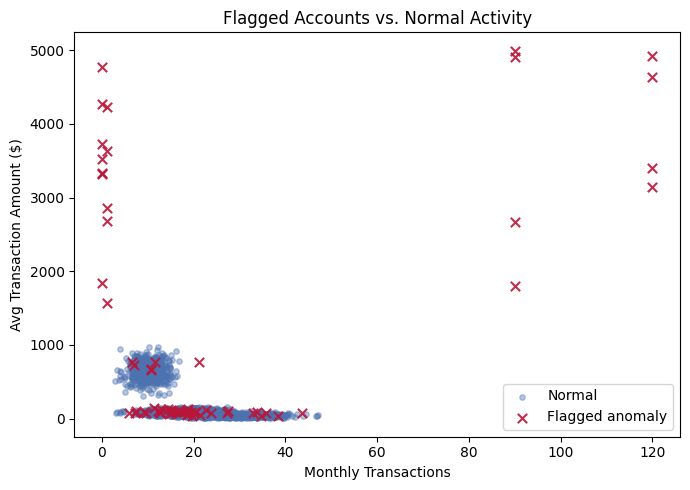

In [ ]:
fig, ax = plt.subplots()

normal_mask = customers["anomaly_flag"] == 0
flagged_mask = customers["anomaly_flag"] == 1

ax.scatter(
    customers.loc[normal_mask, "monthly_transactions"],
    customers.loc[normal_mask, "avg_transaction_amount"],
    s=15, alpha=0.4, color="#1E365C", label="Normal",
)
ax.scatter(
    customers.loc[flagged_mask, "monthly_transactions"],
    customers.loc[flagged_mask, "avg_transaction_amount"],
    s=45, alpha=0.9, color="#BA1538", marker="x", label="Flagged anomaly",
)

ax.set_xlabel("Monthly Transactions")
ax.set_ylabel("Avg Transaction Amount ($)")
ax.set_title("Flagged Accounts vs. Normal Activity")
ax.legend()
plt.tight_layout()
plt.show()


---
## 3. Day 1, Part B — Understanding the Customer Base

Remove the flagged accounts, then let DBSCAN find natural customer segments — without
ever telling it there are three, or what they should look like.

Think about which features actually help separate customers by *behavior*, versus
which ones (like recency or ticket count) were more useful for spotting anomalies than
for describing segments.


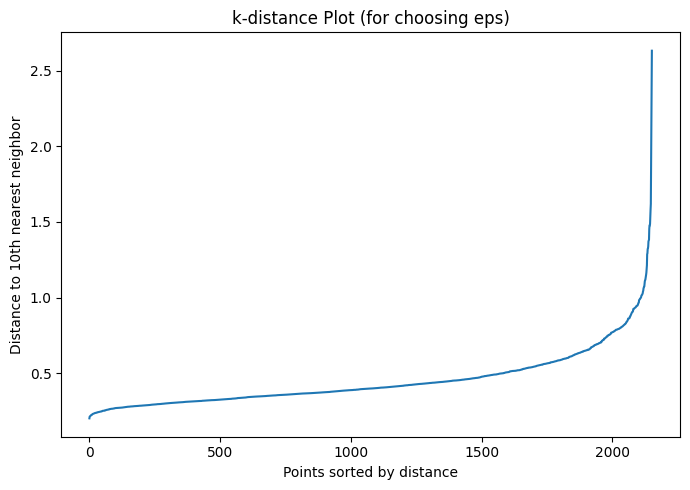

Chosen eps (90th percentile of k-distances): 0.689

Cluster sizes (-1 = noise):
cluster
-1      62
 0    1610
 1     480
Name: count, dtype: int64


In [ ]:

clean_customers = customers.loc[customers["anomaly_flag"] == 0].reset_index(drop=True)


CLUSTER_FEATURES = [
    "monthly_transactions", "avg_transaction_amount",
    "avg_distance_from_home_mi", "monthly_logins",
]

cluster_scaler = StandardScaler()
X_cluster = cluster_scaler.fit_transform(clean_customers[CLUSTER_FEATURES])


min_samples = 10
neighbors = np.sort(
    np.linalg.norm(X_cluster[:, None, :] - X_cluster[None, :, :], axis=-1), axis=1
)[:, min_samples]
k_distances = np.sort(neighbors)

plt.plot(k_distances)
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {min_samples}th nearest neighbor")
plt.title("k-distance Plot (for choosing eps)")
plt.tight_layout()
plt.show()

eps = np.percentile(k_distances, 90)
print(f"Chosen eps (90th percentile of k-distances): {eps:.3f}")

dbscan = DBSCAN(eps=eps, min_samples=min_samples)
clean_customers["cluster"] = dbscan.fit_predict(X_cluster)

print("\nCluster sizes (-1 = noise):")
print(clean_customers["cluster"].value_counts().sort_index())


### Cluster Profiling: Turning Cluster IDs into Personas

Describe each cluster by its average behavior, then assign it a business-readable name.


In [ ]:
cluster_profile = clean_customers.groupby("cluster")[CLUSTER_FEATURES].mean().round(1)
print("Cluster average behavior:")
display(cluster_profile)

def name_persona(row):
    if row["avg_transaction_amount"] > 300:
        return "Small Business Owner"
    elif row["monthly_transactions"] > 22:
        return "Young Professional"
    else:
        return "Growing Family"

persona_map = {}
for cluster_id in cluster_profile.index:
    if cluster_id == -1:
        persona_map[cluster_id] = "Unclassified"
    else:
        persona_map[cluster_id] = name_persona(cluster_profile.loc[cluster_id])

clean_customers["persona"] = clean_customers["cluster"].map(persona_map)

print("\nCluster -> persona mapping:")
print(persona_map)

print("\nAssigned persona vs. hidden ground-truth segment:")
print(pd.crosstab(clean_customers["persona"], clean_customers["segment"]))


Cluster average behavior:


,monthly_transactions,avg_transaction_amount,avg_distance_from_home_mi,monthly_logins
cluster,,,,
-1,21.2,190.3,11.4,20.3
0,23.4,68.0,4.6,17.1
1,10.1,649.8,3.0,15.3



Cluster -> persona mapping:
{-1: 'Unclassified', 0: 'Young Professional', 1: 'Small Business Owner'}

Assigned persona vs. hidden ground-truth segment:
segment               Growing Family  Small Business Owner  Young Professional
persona                                                                       
Small Business Owner               0                   480                   0
Unclassified                      20                    14                  28
Young Professional               742                     0                 868


In [9]:
print([name for name in globals() if not name.startswith("_")])

['In', 'Out', 'get_ipython', 'exit', 'quit', 'open', 'np', 'pd', 'plt', 'IsolationForest', 'MLPRegressor', 'StandardScaler', 'DBSCAN', 'PCA', 'train_test_split', 'roc_auc_score', 'average_precision_score', 'classification_report', 'ConfusionMatrixDisplay', 'precision_recall_curve', 'lgb', 'shap', 'LimeTabularExplainer', 'RANDOM_STATE', 'pca']


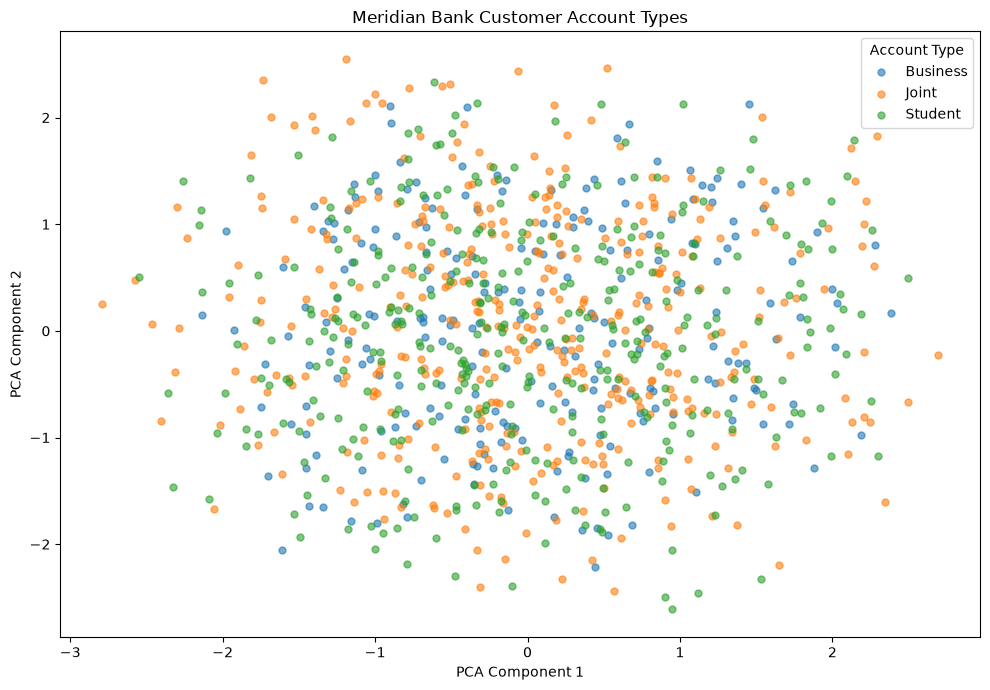


Account Type Distribution:
account_type
Joint       398
Student     363
Business    239
Name: count, dtype: int64

Explained Variance:
[0.21832391 0.20921216]


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# --------------------------------------------------
# 1. Create customer data
# --------------------------------------------------

np.random.seed(RANDOM_STATE)

n_customers = 1000

customers = pd.DataFrame({
    "income": np.random.randint(20000, 200000, n_customers),
    "transactions": np.random.randint(5, 100, n_customers),
    "login_frequency": np.random.randint(1, 30, n_customers),
    "credit_utilization": np.random.uniform(0, 1, n_customers),
    "support_tickets": np.random.randint(0, 10, n_customers),
    "account_type": np.random.choice(
        ["Joint", "Student", "Business"],
        n_customers,
        p=[0.35, 0.40, 0.25]
    )
})

# --------------------------------------------------
# 2. Select numerical features for PCA
# --------------------------------------------------

features = [
    "income",
    "transactions",
    "login_frequency",
    "credit_utilization",
    "support_tickets"
]

X = customers[features]

# --------------------------------------------------
# 3. Standardize the features
# --------------------------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# --------------------------------------------------
# 4. PCA → 2 dimensions
# --------------------------------------------------

pca = PCA(
    n_components=2,
    random_state=RANDOM_STATE
)

X_pca = pca.fit_transform(X_scaled)

customers["pca_1"] = X_pca[:, 0]
customers["pca_2"] = X_pca[:, 1]

# --------------------------------------------------
# 5. Plot the three account types
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 7))

for account_type, group in customers.groupby("account_type"):

    ax.scatter(
        group["pca_1"],
        group["pca_2"],
        s=25,
        alpha=0.6,
        label=account_type
    )

ax.set_xlabel("PCA Component 1")
ax.set_ylabel("PCA Component 2")
ax.set_title("Meridian Bank Customer Account Types")

ax.legend(title="Account Type")

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. Display account counts
# --------------------------------------------------

print("\nAccount Type Distribution:")
print(customers["account_type"].value_counts())

print("\nExplained Variance:")
print(pca.explained_variance_ratio_)

### A Lightweight Persona-Based Recommender

A full collaborative-filtering system is out of scope here, but the same *'people like
you'* idea is easy to demonstrate: once a customer has a persona, recommend whatever
product similar customers most often hold.


In [ ]:
persona_product_map = {
    "Young Professional": "High-Yield Savings + Round-Up Investing",
    "Growing Family": "Family Rewards Credit Card + 529 Savings Plan",
    "Small Business Owner": "Business Line of Credit + Merchant Services",
    "Unclassified": "Standard Checking (needs manual review)",
}

clean_customers["recommended_product"] = clean_customers["persona"].map(persona_product_map)

print("Example customers with persona and recommended product:")
display(
    clean_customers[
        ["customer_id", "persona", "avg_transaction_amount", "monthly_transactions",
         "recommended_product"]
    ].sample(8, random_state=RANDOM_STATE)
)


Example customers with persona and recommended product:


,customer_id,persona,avg_transaction_amount,monthly_transactions,recommended_product
1505,CUST01550,Small Business Owner,710.577664,12.780152,Business Line of Credit + Merchant Services
1660,CUST01715,Young Professional,48.471689,21.300853,High-Yield Savings + Round-Up Investing
889,CUST00923,Young Professional,73.236744,14.930654,High-Yield Savings + Round-Up Investing
306,CUST00320,Small Business Owner,552.862548,12.344974,Business Line of Credit + Merchant Services
1771,CUST01828,Small Business Owner,451.166746,7.269700,Business Line of Credit + Merchant Services
109,CUST00113,Small Business Owner,667.169454,13.018564,Business Line of Credit + Merchant Services
1649,CUST01704,Young Professional,93.027694,17.166162,High-Yield Savings + Round-Up Investing
1655,CUST01710,Small Business Owner,544.764587,7.960735,Business Line of Credit + Merchant Services


---
## 4. Day 1 Outcome: One Customer-Intelligence Table for Two Teams

Merge the anomaly-detection output and the persona/recommendation output back into a
single table — one weekly pipeline, feeding both the fraud team and the marketing team.


In [ ]:
anomaly_cols = ["customer_id", "anomaly_flag", "anomaly_score"]
persona_cols = ["customer_id", "persona", "recommended_product"]

customer_intelligence = customers[anomaly_cols].merge(
    clean_customers[persona_cols], on="customer_id", how="left"
)

# Customers flagged as anomalies never went through clustering -- mark them
# explicitly rather than leaving nulls, so downstream consumers know why.
customer_intelligence["persona"] = customer_intelligence["persona"].fillna("Flagged for Review")
customer_intelligence["recommended_product"] = customer_intelligence["recommended_product"].fillna(
    "Withheld pending fraud review"
)

print(f"customer_intelligence table: {len(customer_intelligence)} rows")
customer_intelligence.head(10)


customer_intelligence table: 2220 rows


,customer_id,anomaly_flag,anomaly_score,persona,recommended_product
0,CUST00000,0,0.034790,Young Professional,High-Yield Savings + Round-Up Investing
1,CUST00001,0,0.054851,Young Professional,High-Yield Savings + Round-Up Investing
2,CUST00002,0,0.071435,Young Professional,High-Yield Savings + Round-Up Investing
3,CUST00003,0,0.049581,Young Professional,High-Yield Savings + Round-Up Investing
4,CUST00004,0,0.054262,Young Professional,High-Yield Savings + Round-Up Investing
5,CUST00005,0,0.119192,Young Professional,High-Yield Savings + Round-Up Investing
6,CUST00006,0,0.106449,Unclassified,Standard Checking (needs manual review)
7,CUST00007,0,0.043432,Young Professional,High-Yield Savings + Round-Up Investing
8,CUST00008,0,0.052558,Young Professional,High-Yield Savings + Round-Up Investing
9,CUST00009,0,0.110872,Young Professional,High-Yield Savings + Round-Up Investing


---
## 5. Day 2 — A Connected Loan-Application Dataset

This is the key link between the two days: each simulated loan applicant's **persona**
and **anomaly score from Day 1** should become real input features for Day 2's
credit-risk model.


In [ ]:
np.random.seed(RANDOM_STATE)
n = len(customer_intelligence)

loan_apps = customer_intelligence.copy()

loan_apps["annual_income"] = np.random.lognormal(mean=10.9, sigma=0.4, size=n).clip(20000, 300000)
loan_apps["debt_to_income"] = np.random.beta(2, 5, n) * 0.8  # 0 - ~0.8
loan_apps["credit_utilization"] = np.random.beta(2, 4, n)   # 0 - 1
loan_apps["employment_years"] = np.random.gamma(2, 3, n).clip(0, 40)
loan_apps["loan_amount_requested"] = np.random.lognormal(mean=9.5, sigma=0.5, size=n).clip(1000, 100000)

# Build a default probability with real, learnable signal from DTI and
# utilization, nudged by the Day 1 anomaly score -- linking the two days.
risk_logit = (
    -4.4
    + 6.0 * loan_apps["debt_to_income"]
    + 4.0 * loan_apps["credit_utilization"]
    - 0.05 * loan_apps["employment_years"]
    - 0.00001 * loan_apps["annual_income"]
    + 1.5 * loan_apps["anomaly_score"]
)
default_prob = 1 / (1 + np.exp(-risk_logit))
loan_apps["defaulted"] = np.random.binomial(1, default_prob.clip(0.01, 0.9))

default_rate = loan_apps["defaulted"].mean()
print(f"Simulated default rate: {default_rate:.1%}")
loan_apps.head()


Simulated default rate: 11.5%


,customer_id,anomaly_flag,anomaly_score,persona,recommended_product,annual_income,debt_to_income,credit_utilization,employment_years,loan_amount_requested,defaulted
0,CUST00000,0,0.034790,Young Professional,High-Yield Savings + Round-Up Investing,66084.245975,0.214356,0.348603,2.615830,18458.996596,0
1,CUST00001,0,0.054851,Young Professional,High-Yield Savings + Round-Up Investing,51261.449633,0.084454,0.074931,2.518409,9231.386793,0
2,CUST00002,0,0.071435,Young Professional,High-Yield Savings + Round-Up Investing,70198.022159,0.024949,0.160295,1.677326,9001.218836,0
3,CUST00003,0,0.049581,Young Professional,High-Yield Savings + Round-Up Investing,99629.336419,0.022366,0.364800,5.711153,10353.793380,0
4,CUST00004,0,0.054262,Young Professional,High-Yield Savings + Round-Up Investing,49332.513718,0.294381,0.286695,9.215083,11781.450991,0


In [ ]:
persona_dummies = pd.get_dummies(loan_apps["persona"], prefix="persona")

FEATURE_COLS = [
    "annual_income", "debt_to_income", "credit_utilization",
    "employment_years", "loan_amount_requested", "anomaly_score",
] + list(persona_dummies.columns)

X = pd.concat([loan_apps[FEATURE_COLS[:6]], persona_dummies], axis=1)
y = loan_apps["defaulted"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train default rate: {y_train.mean():.1%} | Test default rate: {y_test.mean():.1%}")


Train: (1665, 10), Test: (555, 10)
Train default rate: 11.5% | Test default rate: 11.5%


---
## 6. Predicting Credit Risk with LightGBM

Use class weighting (or another imbalance strategy) to handle the fact that defaults
are a minority class -- a model that ignores this will just learn to predict
'no default' every time.


In [ ]:
model = lgb.LGBMClassifier(
    n_estimators=400,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    verbosity=-1,
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_test, y_test)],
    eval_metric="average_precision",
    callbacks=[lgb.early_stopping(30, verbose=False)],
)

y_proba = model.predict_proba(X_test)[:, 1]
y_pred = model.predict(X_test)

roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

print(f"Best iteration: {model.best_iteration_}")
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC (Average Precision): {pr_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Best iteration: 26
ROC-AUC: 0.7532
PR-AUC (Average Precision): 0.4063

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.80      0.86       491
           1       0.25      0.52      0.34        64

    accuracy                           0.76       555
   macro avg       0.59      0.66      0.60       555
weighted avg       0.85      0.76      0.80       555



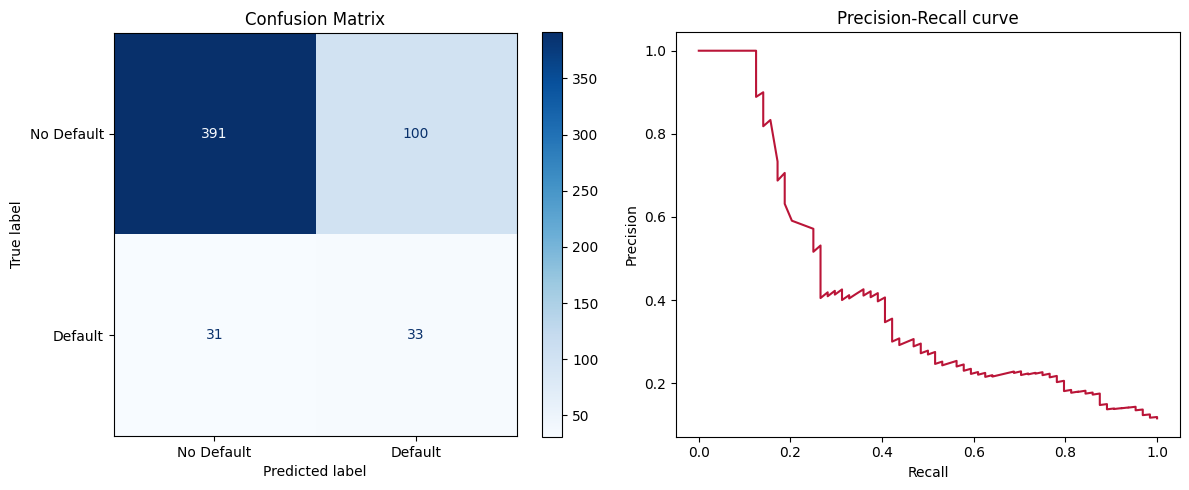

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["No Default", "Default"],
    cmap="Blues", ax=axes[0],
)
axes[0].set_title("Confusion Matrix")

precision, recall, _ = precision_recall_curve(y_test, y_proba)
axes[1].plot(recall, precision, color="#BA1538")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curve")

plt.tight_layout()
plt.show()


---
## 7. Explaining Every Decision — SHAP, LIME, and Feature Importance


/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:632: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
/tmp/ipykernel_2710/4123289260.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_to_plot, X_test, show=True)


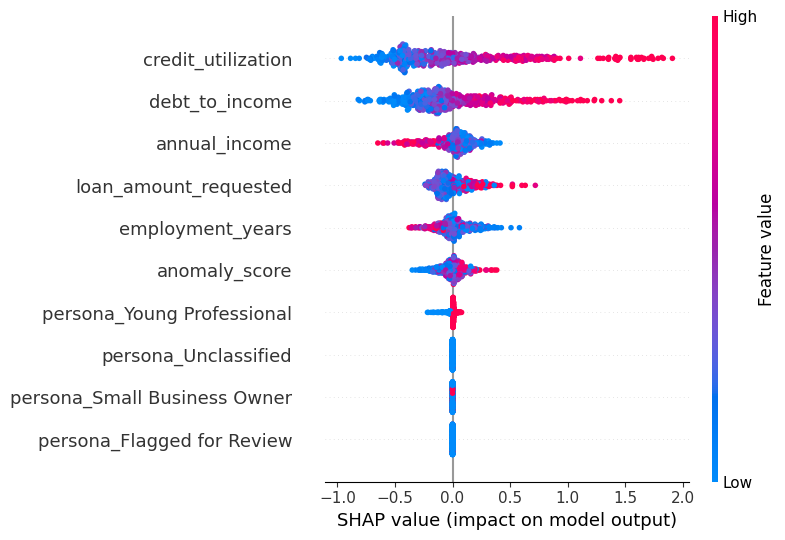

In [ ]:
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

if isinstance(shap_values, list):
    shap_values_to_plot = shap_values[1]  # positive class (default)
else:
    shap_values_to_plot = shap_values

shap.summary_plot(shap_values_to_plot, X_test, show=True)


In [ ]:
feature_importance = pd.DataFrame({
    "feature": X_test.columns,
    "mean_abs_shap": np.abs(shap_values_to_plot).mean(axis=0),
}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

print("Feature importance ranking (by mean |SHAP value|):")
display(feature_importance)

persona_features = [c for c in feature_importance["feature"] if c.startswith("persona_")]
top_feature = feature_importance.iloc[0]["feature"]
persona_rank = feature_importance[feature_importance["feature"].isin(persona_features)].index.min()

print(f"\nTop-ranked feature overall: {top_feature}")
if persona_rank is not None and persona_rank == 0:
    print("WARNING: a persona feature is the single most important driver -- "
          "investigate before shipping, this could be a proxy for a protected attribute.")
else:
    print("Persona features are not dominating the ranking above traditional "
          "financial factors (income, DTI, utilization) -- no immediate fairness "
          "red flag from this check.")


Feature importance ranking (by mean |SHAP value|):


,feature,mean_abs_shap
0,credit_utilization,0.430445
1,debt_to_income,0.294446
2,annual_income,0.127355
3,loan_amount_requested,0.110020
4,employment_years,0.098988
5,anomaly_score,0.075226
6,persona_Young Professional,0.017754
7,persona_Flagged for Review,0.000000
8,persona_Small Business Owner,0.000000
9,persona_Unclassified,0.000000



Top-ranked feature overall: credit_utilization
Persona features are not dominating the ranking above traditional financial factors (income, DTI, utilization) -- no immediate fairness red flag from this check.


### One Applicant, Explained Two Ways


In [ ]:
most_confident_idx = np.argmax(y_proba)

applicant = X_test.iloc[most_confident_idx]
print(f"Row position in test set: {most_confident_idx}")
print(f"Predicted probability of default: {y_proba[most_confident_idx]:.4f}")
print(f"Actual outcome: {'Default' if y_test.iloc[most_confident_idx] == 1 else 'No Default'}")
print("\nFeature values:")
display(applicant)


Row position in test set: 168
Predicted probability of default: 0.7889
Actual outcome: Default

Feature values:


,336
annual_income,38940.928432
debt_to_income,0.447304
credit_utilization,0.576711
employment_years,3.336806
loan_amount_requested,26140.258759
anomaly_score,0.853225
persona_Flagged for Review,True
persona_Small Business Owner,False
persona_Unclassified,False
persona_Young Professional,False


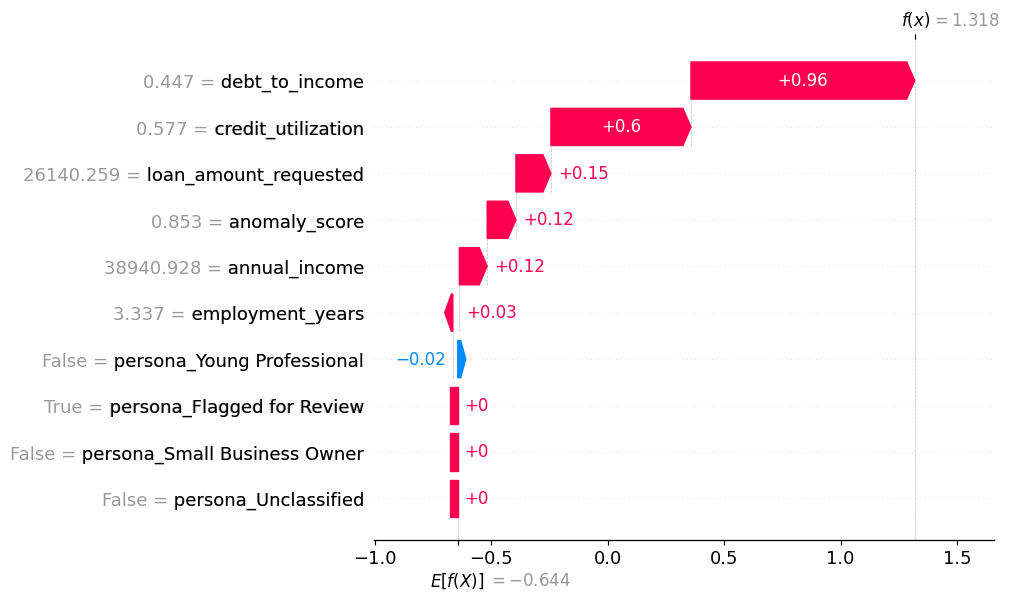

In [ ]:
base_value = (
    explainer.expected_value
    if not isinstance(explainer.expected_value, (list, np.ndarray))
    else (explainer.expected_value[1] if isinstance(explainer.expected_value, list)
          else explainer.expected_value)
)

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_to_plot[most_confident_idx],
        base_values=base_value,
        data=X_test.iloc[most_confident_idx],
        feature_names=X_test.columns.tolist(),
    ),
    max_display=10,
)


In [ ]:
lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=["No Default", "Default"],
    mode="classification",
    random_state=RANDOM_STATE,
)

lime_exp = lime_explainer.explain_instance(
    X_test.iloc[most_confident_idx].values,
    model.predict_proba,
    num_features=8,
)

print("LIME explanation for this applicant:\n")
for feature_desc, weight in lime_exp.as_list():
    direction = "toward DEFAULT" if weight > 0 else "away from default"
    print(f"  {feature_desc:<40}  pushes prediction {direction}  (weight={weight:+.3f})")


LIME explanation for this applicant:

  credit_utilization > 0.45                 pushes prediction toward DEFAULT  (weight=+0.241)
  debt_to_income > 0.31                     pushes prediction toward DEFAULT  (weight=+0.195)
  loan_amount_requested > 18778.12          pushes prediction toward DEFAULT  (weight=+0.051)
  annual_income <= 42388.78                 pushes prediction toward DEFAULT  (weight=+0.039)
  anomaly_score > 0.10                      pushes prediction toward DEFAULT  (weight=+0.035)
  persona_Flagged for Review > 0.00         pushes prediction away from default  (weight=-0.011)
  persona_Young Professional <= 0.00        pushes prediction away from default  (weight=-0.009)
  persona_Unclassified <= 0.00              pushes prediction toward DEFAULT  (weight=+0.007)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


---
## 8. Keeping the Model Honest — A Simple Monthly Drift Check

Simulate two batches of applications (e.g., 'Month 1' and 'Month 2') and compare their
predicted-risk distributions -- the same idea as a production monitoring dashboard,
compressed into one notebook cell.


Month 1 mean predicted risk: 0.3718
Month 2 mean predicted risk: 0.5220
Drift (Month 2 - Month 1): +0.1502
ALERT: drift exceeds threshold of 0.03 -- flag for retraining review.


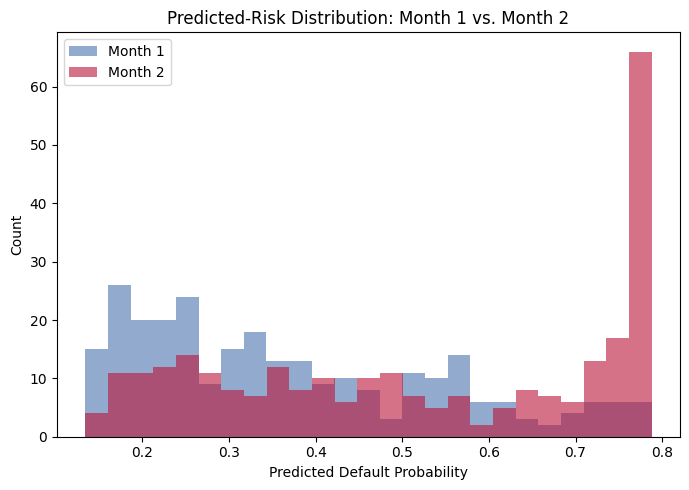

In [ ]:
batch_1, batch_2 = train_test_split(
    X_test, test_size=0.5, random_state=RANDOM_STATE
)

# Simulate a genuine shift in Month 2: applicants running a bit riskier
# (higher debt-to-income), the way a real drifted batch might look.
batch_2_shifted = batch_2.copy()
batch_2_shifted["debt_to_income"] = (batch_2_shifted["debt_to_income"] * 1.6).clip(0, 1)
batch_2_shifted["credit_utilization"] = (batch_2_shifted["credit_utilization"] * 1.4).clip(0, 1)

month_1_scores = model.predict_proba(batch_1)[:, 1]
month_2_scores = model.predict_proba(batch_2_shifted)[:, 1]

mean_1, mean_2 = month_1_scores.mean(), month_2_scores.mean()
drift = mean_2 - mean_1
DRIFT_THRESHOLD = 0.03  # absolute shift in mean predicted risk

print(f"Month 1 mean predicted risk: {mean_1:.4f}")
print(f"Month 2 mean predicted risk: {mean_2:.4f}")
print(f"Drift (Month 2 - Month 1): {drift:+.4f}")

if abs(drift) > DRIFT_THRESHOLD:
    print(f"ALERT: drift exceeds threshold of {DRIFT_THRESHOLD} -- flag for retraining review.")
else:
    print(f"No alert: drift is within the {DRIFT_THRESHOLD} threshold.")

plt.hist(month_1_scores, bins=25, alpha=0.6, label="Month 1", color="#4C72B0")
plt.hist(month_2_scores, bins=25, alpha=0.6, label="Month 2", color="#BA1538")
plt.xlabel("Predicted Default Probability")
plt.ylabel("Count")
plt.title("Predicted-Risk Distribution: Month 1 vs. Month 2")
plt.legend()
plt.tight_layout()
plt.show()


---
## 9. Bringing It Together — One Customer, Start to Finish

Take one applicant and trace them through the *entire* two-day pipeline: persona and
anomaly score from Day 1, risk score and explanation from Day 2, and the final decision
plus personalized offer.


In [1]:
report_idx = most_confident_idx
applicant_row = loan_apps.loc[X_test.iloc[[report_idx]].index[0]]
applicant_features = X_test.iloc[report_idx]
risk_score = y_proba[report_idx]
decision = "DECLINE" if risk_score >= 0.5 else "APPROVE"

top_driver_idx = np.argmax(np.abs(shap_values_to_plot[report_idx]))
top_driver_feature = X_test.columns[top_driver_idx]
top_driver_value = shap_values_to_plot[report_idx][top_driver_idx]
top_driver_direction = "increased" if top_driver_value > 0 else "decreased"

print("=" * 60)
print(f"UNIFIED CUSTOMER REPORT — {applicant_row['customer_id']}")
print("=" * 60)
print(f"Day 1 persona:            {applicant_row['persona']}")
print(f"Day 1 anomaly score:      {applicant_row['anomaly_score']:.3f}")
print(f"Day 2 predicted risk:     {risk_score:.1%}")
print(f"Day 2 decision:           {decision}")
print(f"Top SHAP driver:          {top_driver_feature} "
      f"({top_driver_direction} default risk, impact={top_driver_value:+.3f})")

if decision == "APPROVE":
    offer = persona_product_map.get(applicant_row["persona"], "Standard product bundle")
    print(f"Next-best-offer:          {offer}")
else:
    print("Next-best-offer:          Withheld -- application flagged for manual review")
print("=" * 60)


NameError: name 'most_confident_idx' is not defined

## Summary

Once complete, this notebook should show the entire case study end to end:

- **Day 1** turning raw, unlabeled customer activity into real-time fraud flags and
  named personas.
- **Day 1 → Day 2** those same outputs becoming real model features, not just a report.
- **Day 2** training an accurate, imbalance-aware credit-risk model, then explaining it
  globally and one decision at a time.
- **Monitoring** giving the model a simple, honest way to flag when it's time to
  retrain.

### Ideas to extend this notebook once it's working
- Swap in `CatBoostClassifier` for the persona features left as raw categories instead
  of one-hot columns, and compare SHAP explanations.
- Try `SMOTE` (from `imbalanced-learn`) instead of class weighting and compare PR-AUC.
- Replace the rule-based recommender with a real collaborative-filtering model once
  more transaction-level, item-level data is available.
